# Trabalho 12 — Compressão de imagens
## RLE (Run-Length Encoded) sobre arquivos PPM

**Disciplina:** Computação Gráfica / Processamento de Imagens Digitais
**Professor:** André Alessandro Stein / Cristhian Heck
**Aluno:** Igor
**Instituição:** IFC — Campus Rio do Sul

### Tarefa

Conforme as seções *Implementação* e *Descompressão* do material
`CompressãoImagens.pdf`:

**Compressão** — ler um arquivo `.PPM`, guardar a imagem em variável
multidimensional, percorrê-la linha a linha e, para cada linha e cada cor básica
(R, G, B), aplicar o algoritmo RLE. Antes de comprimir, gravar a largura `l` e a
altura `h` da imagem original.

**Descompressão** — a partir do arquivo RLE, recuperar `l` e `h`, escrever o
cabeçalho PPM e reconstruir o conteúdo, lendo os contadores como `signed char`:

- contador **positivo** → repetir o valor seguinte tantas vezes quanto o contador
- contador **negativo** → indica quantos valores seguintes são de píxeis distintos

### Por que o resultado importa mais que o código

O RLE é simples de implementar. O que torna esta atividade interessante é
**medir** o que ele entrega: sobre uma imagem fotográfica o ganho é modesto, e
em certos casos o algoritmo chega a **aumentar** o tamanho do arquivo. O notebook
quantifica os dois extremos.

### Referências

- STEIN, A. A.; HECK, C. *Compressão de Imagens*, 2022/2 — seção 13.4.
- LOPES, J. M. Brisson. *Formatos de Imagem*. DEI — IST, Lisboa, 2003 (reed. 2013).

## 1. Fundamentação

### A ideia do RLE

O material enuncia a premissa com precisão: se escolhermos um píxel ao acaso,
há grande probabilidade de que seus vizinhos tenham a mesma cor. O compressor
varre o pixmap à procura de subsequências de píxeis iguais e substitui cada uma
por um par `(número de píxeis, cor)`.

A apostila de formatos descreve o mesmo princípio e já aponta onde ele funciona:
a ocorrência de grupos de píxeis consecutivos da mesma cor "propicia o emprego
de algoritmos de compressão do tipo RLE", sendo comum em gráficos e esquemas e
rara em imagens de qualidade fotográfica.

### O problema da ambiguidade

Codificar apenas pares `(contador, valor)` é ineficiente quando os píxeis não se
repetem: uma sequência de 4 valores distintos viraria 8 bytes — o dobro.

A solução adotada pelo material é distinguir dois tipos de bloco pelo **sinal**
do contador:

| Contador | Significado | Bytes consumidos |
|----------|-------------|------------------|
| `+k` (positivo) | o próximo valor se repete `k` vezes | 2 |
| `−m` (negativo) | os próximos `m` valores são literais | `m + 1` |

Esse esquema é conhecido como **PackBits** e é o mesmo empregado pelo formato
TIFF. O limite de 127 por bloco vem de o contador ser um `signed char`: se mais
de 127 valores iguais aparecerem seguidos, divide-se em grupos — o material dá o
exemplo de 600 repetições de 12 codificadas como `127,12 127,12 127,12 127,12
92,12`.

### O "?" do exemplo do material

O material apresenta a sequência codificada com uma incógnita:

    9,12, -4, 35, 76, 112, 67, 3, 87, 6, 5, ?, 1, ...

e explica que "o valor em `?` só será determinado depois de ser conhecido o
resto da sequência". A razão é que o contador de um bloco literal precisa saber
**quantos** valores distintos virão, o que só se sabe ao encontrar a próxima
repetição ou o fim da linha. No exemplo truncado, se a sequência terminar no `1`,
o valor é `−1`. A implementação verifica isso.

### Organização por linha e por canal

O material é explícito: a compressão é feita **linha a linha**, e cada linha da
imagem corresponde a três "linhas" codificadas, na ordem R, G, B.

Essa escolha tem consequência direta no resultado. Separar os canais agrupa
valores correlacionados — numa região de céu, o canal azul tem corridas longas
mesmo que a cor completa do píxel varie. Já reiniciar a codificação a cada linha
impede que uma corrida atravesse a quebra de linha, o que custa alguns bytes mas
mantém o formato decodificável linha a linha, como a seção de descompressão
descreve.

In [1]:
# Bibliotecas e configuração

import textwrap
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

BASE = Path.cwd()
ENTRADA = BASE / "entrada"
SAIDA = BASE / "saida"
SAIDA.mkdir(exist_ok=True)

NOME_IMAGEM = "Fig4.ppm"
ARQUIVO_ENTRADA = ENTRADA / NOME_IMAGEM

LIMITE_COLUNA = 70
MAX_BLOCO = 127          # contador cabe em um signed char

print(f"Entrada existe : {ARQUIVO_ENTRADA.exists()}")
print(f"Bloco máximo   : {MAX_BLOCO} valores")

Entrada existe : True
Bloco máximo   : 127 valores


In [2]:
# --- Leitor e escritor PPM P3 (reaproveitados) ---

def _fluxo_tokens(arquivo):
    for linha in arquivo:
        util = linha.split("#", 1)[0]
        for token in util.split():
            yield token


def ler_ppm_p3(caminho):
    """Lê um PPM tipo P3 e devolve (matriz (altura, largura, 3), maxval)."""
    with open(caminho, "r", encoding="ascii") as f:
        it = _fluxo_tokens(f)
        magic = next(it)
        if magic != "P3":
            raise ValueError(f"Magic number inesperado: {magic!r}")

        largura, altura, maxval = (int(next(it)) for _ in range(3))
        esperados = largura * altura * 3
        dados = np.fromiter(map(int, it), dtype=np.uint8, count=esperados)

    if dados.size != esperados:
        raise ValueError(f"Esperados {esperados} valores, lidos {dados.size}")

    return dados.reshape(altura, largura, 3), maxval


def escrever_ppm_p3(caminho, imagem, maxval, comentario=None):
    """Grava uma matriz (altura, largura, 3) como PPM tipo P3."""
    imagem = np.asarray(imagem)
    altura, largura, _ = imagem.shape

    n = max(1, (LIMITE_COLUNA + 1) // (len(str(maxval)) + 1))
    n = max(3, n - (n % 3))
    plano = imagem.reshape(-1).tolist()

    with open(caminho, "w", encoding="ascii", newline="\n") as f:
        f.write("P3\n")
        if comentario:
            for trecho in textwrap.wrap(comentario, width=LIMITE_COLUNA - 2):
                f.write(f"# {trecho}\n")
        f.write(f"{largura} {altura}\n{maxval}\n")
        linhas = [" ".join(map(str, plano[i:i + n]))
                  for i in range(0, len(plano), n)]
        f.write("\n".join(linhas) + "\n")

    return caminho

## 2. O codificador RLE

A função trabalha sobre **uma sequência** — uma linha de um canal — e devolve a
lista de valores codificados, com contadores positivos para repetições e
negativos para literais.

### Decisão de projeto: quando vale repetir

Uma corrida de 2 valores iguais custa 2 bytes codificada como repetição
(`2, v`) e 3 bytes como literal (`-2, v, v`). Já uma corrida de 2 **dentro** de
um bloco literal maior custa apenas os 2 bytes dos próprios valores.

Implementações mais sofisticadas fazem essa análise global. Adoto a regra
simples — toda corrida de 2 ou mais vira repetição — porque é a que reproduz o
exemplo do material, e a diferença é de fração de por cento.

### Validação contra o exemplo do material

A sequência do PDF serve de teste. Se a saída coincidir, incluindo a resolução
do `?`, o codificador está correto.

In [3]:
# --- Codificador RLE ---

def comprimir_sequencia(seq, max_bloco=MAX_BLOCO):
    """
    Codifica uma sequência pelo esquema do material (PackBits).

    Contador positivo k -> o valor seguinte se repete k vezes.
    Contador negativo -m -> os m valores seguintes são literais.
    Nenhum bloco excede max_bloco valores.
    """
    saida = []
    i, n = 0, len(seq)

    while i < n:
        # Mede a corrida de valores iguais a partir de i
        j = i
        while j + 1 < n and seq[j + 1] == seq[j]:
            j += 1
        corrida = j - i + 1

        if corrida >= 2:
            # Bloco de repetição, dividido se exceder o limite
            while corrida > 0:
                k = min(corrida, max_bloco)
                saida.append(k)
                saida.append(seq[i])
                corrida -= k
                i += k
        else:
            # Bloco literal: avança enquanto não houver repetição
            j = i
            while (j < n and (j + 1 >= n or seq[j + 1] != seq[j])
                   and j - i < max_bloco):
                j += 1
            saida.append(-(j - i))
            saida.extend(seq[i:j])
            i = j

    return saida


# --- Teste contra o exemplo do material ---

exemplo = [12] * 9 + [35, 76, 112, 67] + [87] * 3 + [5] * 6 + [1]
codificado = comprimir_sequencia(exemplo)

print("Sequência de entrada (material):")
print(f"  {exemplo}")
print()
print("Codificada:")
print(f"  {codificado}")
print()
print("Material:")
print("  [9, 12, -4, 35, 76, 112, 67, 3, 87, 6, 5, ?, 1]")
print()

esperado = [9, 12, -4, 35, 76, 112, 67, 3, 87, 6, 5, -1, 1]
assert codificado == esperado
print("Confere com o material em todas as posições.")
print(f"O '?' do PDF resolve como {esperado[-2]}: um bloco literal de um único")
print("valor, já que a sequência termina no 1 e não há mais repetições.")
print()
print(f"Tamanho: {len(exemplo)} valores -> {len(codificado)} valores "
      f"({len(exemplo) / len(codificado):.2f}x)")

Sequência de entrada (material):
  [12, 12, 12, 12, 12, 12, 12, 12, 12, 35, 76, 112, 67, 87, 87, 87, 5, 5, 5, 5, 5, 5, 1]

Codificada:
  [9, 12, -4, 35, 76, 112, 67, 3, 87, 6, 5, -1, 1]

Material:
  [9, 12, -4, 35, 76, 112, 67, 3, 87, 6, 5, ?, 1]

Confere com o material em todas as posições.
O '?' do PDF resolve como -1: um bloco literal de um único
valor, já que a sequência termina no 1 e não há mais repetições.

Tamanho: 23 valores -> 13 valores (1.77x)


In [4]:
# --- Teste do limite de 127 ---

# O material: "se 12 aparecesse 600 vezes seguidas, ficaria
# 127,12 127,12 127,12 127,12 92,12"
longo = [12] * 600
cod_longo = comprimir_sequencia(longo)

print("600 repetições de 12:")
print(f"  calculado: {cod_longo}")
print(f"  material : [127, 12, 127, 12, 127, 12, 127, 12, 92, 12]")

assert cod_longo == [127, 12, 127, 12, 127, 12, 127, 12, 92, 12]
print("\nConfere. 4 blocos de 127 mais um de 92 somam exatamente 600.")

# Teste do caso adverso: sequência sem nenhuma repetição
sem_repeticao = list(range(200))
cod_sem = comprimir_sequencia(sem_repeticao)
print(f"\n200 valores todos distintos:")
print(f"  {len(sem_repeticao)} valores -> {len(cod_sem)} valores "
      f"({len(cod_sem) - len(sem_repeticao):+d})")
print(f"  Blocos literais exigem 1 byte de contador a cada {MAX_BLOCO} valores.")
print(f"  Este é o pior caso do RLE: ele expande os dados.")

600 repetições de 12:
  calculado: [127, 12, 127, 12, 127, 12, 127, 12, 92, 12]
  material : [127, 12, 127, 12, 127, 12, 127, 12, 92, 12]

Confere. 4 blocos de 127 mais um de 92 somam exatamente 600.

200 valores todos distintos:
  200 valores -> 202 valores (+2)
  Blocos literais exigem 1 byte de contador a cada 127 valores.
  Este é o pior caso do RLE: ele expande os dados.


## 3. O formato do arquivo comprimido

O material determina que largura e altura sejam escritas antes dos dados, e que
os contadores sejam lidos como `signed char`. Adoto:

| Parte | Conteúdo |
|-------|----------|
| Cabeçalho | linha ASCII `RLE <largura> <altura> <maxval>\n` |
| Dados | fluxo de bytes, na ordem linha → canal (R, G, B) |

### A sutileza dos tipos

O fluxo mistura dois significados no mesmo byte:

- **Contadores** são `signed char`, faixa `[-128, 127]`. Um valor negativo é
  gravado em complemento de dois: `−4` vira o byte `0xFC` (252).
- **Dados de cor** são `unsigned char`, faixa `[0, 255]`.

O decodificador precisa reinterpretar cada byte conforme a posição em que se
encontra: byte de contador vira signed, byte de dado permanece unsigned. Essa
alternância é o que torna o fluxo decodificável sem separadores — e é também a
fonte de erro mais comum numa implementação desatenta, porque ler um contador
como unsigned transforma `−4` em `252` e o decodificador sai do sincronismo
silenciosamente.

In [5]:
# --- Compressão da imagem completa ---

def comprimir_ppm(imagem, maxval, caminho_saida):
    """
    Comprime a imagem linha a linha, canal a canal, conforme o material.

    Cada linha da imagem gera três sequências codificadas (R, G, B),
    nessa ordem.
    """
    altura, largura, _ = imagem.shape
    bytes_saida = bytearray()

    for y in range(altura):
        for c in range(3):
            for v in comprimir_sequencia(imagem[y, :, c].tolist()):
                # Contadores negativos em complemento de dois
                bytes_saida.append(v & 0xFF)

    with open(caminho_saida, "wb") as f:
        f.write(f"RLE {largura} {altura} {maxval}\n".encode("ascii"))
        f.write(bytes_saida)

    return caminho_saida, len(bytes_saida)


imagem, MAXVAL = ler_ppm_p3(ARQUIVO_ENTRADA)
altura, largura, _ = imagem.shape

ARQUIVO_RLE = SAIDA / f"{ARQUIVO_ENTRADA.stem}.rle"
_, n_bytes_dados = comprimir_ppm(imagem, MAXVAL, ARQUIVO_RLE)

print(f"Imagem         : {largura} x {altura}  ({largura * altura:,} píxeis)")
print(f"Arquivo gerado : {ARQUIVO_RLE.name}")
print(f"Bytes de dados : {n_bytes_dados:,}")
print(f"Tamanho total  : {ARQUIVO_RLE.stat().st_size:,} bytes "
      f"(inclui o cabeçalho)")
print()
print("Primeiros bytes do fluxo (hexadecimal):")
with open(ARQUIVO_RLE, "rb") as f:
    cabecalho = f.readline().decode("ascii").rstrip()
    amostra = f.read(24)
print(f"  cabeçalho: {cabecalho!r}")
print(f"  dados    : {' '.join(f'{b:02X}' for b in amostra)}")

Imagem         : 481 x 321  (154,401 píxeis)
Arquivo gerado : Fig4.rle
Bytes de dados : 399,213
Tamanho total  : 399,229 bytes (inclui o cabeçalho)

Primeiros bytes do fluxo (hexadecimal):
  cabeçalho: 'RLE 481 321 255'
  dados    : 08 04 03 05 02 06 03 07 10 06 08 05 FF 03 02 04 02 05 02 04 FF 03 10 04


In [6]:
# --- Descompressão ---

def descomprimir_rle(caminho):
    """
    Reconstrói a imagem a partir do arquivo RLE.

    Segue o procedimento do material: lê largura e altura do cabeçalho e,
    para cada linha e cada canal, consome blocos somando o valor absoluto
    dos contadores até completar a largura da linha.
    """
    with open(caminho, "rb") as f:
        cabecalho = f.readline().decode("ascii").split()
        if cabecalho[0] != "RLE":
            raise ValueError(f"Cabeçalho inesperado: {cabecalho[0]!r}")
        largura, altura, maxval = (int(v) for v in cabecalho[1:4])
        dados = f.read()

    imagem = np.zeros((altura, largura, 3), dtype=np.uint8)
    pos = 0

    for y in range(altura):
        for c in range(3):
            linha = []
            while len(linha) < largura:
                contador = dados[pos]
                # Reinterpreta o byte do contador como signed char
                if contador > 127:
                    contador -= 256
                pos += 1

                if contador > 0:
                    linha.extend([dados[pos]] * contador)
                    pos += 1
                elif contador < 0:
                    m = -contador
                    linha.extend(dados[pos:pos + m])
                    pos += m
                else:
                    raise ValueError("Contador zero: fluxo corrompido")

            if len(linha) != largura:
                raise ValueError(
                    f"Linha {y}, canal {c}: {len(linha)} valores, "
                    f"esperados {largura}")

            imagem[y, :, c] = linha

    if pos != len(dados):
        raise ValueError(f"Sobraram {len(dados) - pos} bytes não consumidos")

    return imagem, maxval


recuperada, maxval_rec = descomprimir_rle(ARQUIVO_RLE)

print(f"Imagem recuperada : {recuperada.shape[1]} x {recuperada.shape[0]}")
print(f"maxval            : {maxval_rec}")
print(f"Bytes consumidos  : todos (nenhum resíduo no fluxo)")

Imagem recuperada : 481 x 321
maxval            : 255
Bytes consumidos  : todos (nenhum resíduo no fluxo)


COMPRESSÃO SEM PERDA CONFIRMADA
------------------------------------------------------
Píxeis divergentes : 0
Diferença máxima   : 0

Ao contrário da quantização e da binarização das atividades
anteriores, o RLE é perfeitamente reversível: o arquivo comprimido
contém exatamente a mesma informação que o original.

PPM reconstruído : Fig4_recuperada.ppm  (round-trip completo OK)


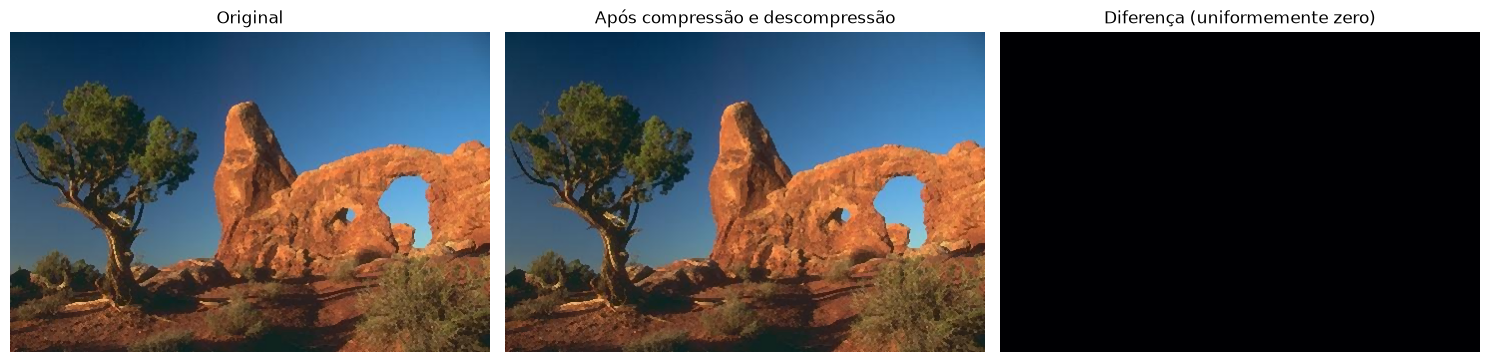

In [7]:
# --- Validação: o RLE é uma compressão SEM perda ---

assert recuperada.shape == imagem.shape
assert maxval_rec == MAXVAL
assert np.array_equal(recuperada, imagem), "A imagem recuperada difere!"

print("COMPRESSÃO SEM PERDA CONFIRMADA")
print("-" * 54)
print(f"Píxeis divergentes : {int((recuperada != imagem).sum())}")
print(f"Diferença máxima   : {int(np.abs(recuperada.astype(int) - imagem.astype(int)).max())}")
print()
print("Ao contrário da quantização e da binarização das atividades")
print("anteriores, o RLE é perfeitamente reversível: o arquivo comprimido")
print("contém exatamente a mesma informação que o original.")

# Grava o PPM reconstruído e confirma que ele é idêntico ao de entrada
PPM_RECUPERADO = SAIDA / f"{ARQUIVO_ENTRADA.stem}_recuperada.ppm"
escrever_ppm_p3(PPM_RECUPERADO, recuperada, MAXVAL,
                comentario=f"reconstruida a partir de {ARQUIVO_RLE.name}")

conferencia, _ = ler_ppm_p3(PPM_RECUPERADO)
assert np.array_equal(conferencia, imagem)
print(f"\nPPM reconstruído : {PPM_RECUPERADO.name}  (round-trip completo OK)")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
eixos[0].imshow(imagem)
eixos[0].set_title("Original")
eixos[1].imshow(recuperada)
eixos[1].set_title("Após compressão e descompressão")
eixos[2].imshow(np.abs(recuperada.astype(int) - imagem.astype(int)).sum(axis=2),
                cmap="inferno", vmin=0, vmax=1)
eixos[2].set_title("Diferença (uniformemente zero)")
for ax in eixos:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Medindo a compressão

### Contra o quê comparar

Esta é a decisão que mais afeta o número final, e é fácil errar.

O arquivo de entrada está em **P3 (ASCII)**, onde cada componente ocupa de 2 a 4
caracteres. Comparar o RLE contra ele produziria uma razão inflada — a maior
parte do ganho viria de abandonar a representação textual, não do RLE.

A comparação honesta é contra o **P6 (binário)**, onde cada componente ocupa
exatamente 1 byte. Essa é a quantidade de dados que o RLE efetivamente recebe.

| Referência | Tamanho | O que mede |
|------------|---------|------------|
| P3 (ASCII) | ~3,4 bytes/componente | texto vs. binário, não compressão |
| **P6 (binário)** | **1 byte/componente** | **o ganho real do RLE** |

A célula abaixo apresenta as duas, com a razão contra o P6 como resultado.

In [8]:
# --- Métricas de compressão ---

n_componentes = largura * altura * 3
tam_p6 = n_componentes                     # 1 byte por componente
tam_p3 = ARQUIVO_ENTRADA.stat().st_size
tam_rle = ARQUIVO_RLE.stat().st_size

print(f"{'Representação':<32}{'Bytes':>14}{'vs. P6':>10}")
print("-" * 58)
print(f"{'P3 (ASCII, arquivo de entrada)':<32}{tam_p3:>14,}{tam_p3 / tam_p6:>9.2f}x")
print(f"{'P6 (binário, referência)':<32}{tam_p6:>14,}{1.0:>9.2f}x")
print(f"{'RLE (esta implementação)':<32}{tam_rle:>14,}{tam_rle / tam_p6:>9.2f}x")
print()
print(f"RAZÃO DE COMPRESSÃO (P6 -> RLE) : {tam_p6 / tam_rle:.3f}x")
print(f"ESPAÇO ECONOMIZADO               : {(1 - tam_rle / tam_p6) * 100:.1f}%")
print()
print(f"Para efeito de contraste, a razão contra o P3 seria "
      f"{tam_p3 / tam_rle:.2f}x — mas esse número mede sobretudo a troca de")
print("ASCII por binário, não o trabalho do algoritmo de compressão.")

Representação                            Bytes    vs. P6
----------------------------------------------------------
P3 (ASCII, arquivo de entrada)       1,557,748     3.36x
P6 (binário, referência)               463,203     1.00x
RLE (esta implementação)               399,229     0.86x

RAZÃO DE COMPRESSÃO (P6 -> RLE) : 1.160x
ESPAÇO ECONOMIZADO               : 13.8%

Para efeito de contraste, a razão contra o P3 seria 3.90x — mas esse número mede sobretudo a troca de
ASCII por binário, não o trabalho do algoritmo de compressão.


ANATOMIA DO FLUXO CODIFICADO
----------------------------------------------------------
Blocos de repetição :   372,643  cobrindo 27,078,915 componentes ( 99.0%)
Blocos literais     :    26,561  cobrindo   264,556 componentes (  1.0%)

Comprimento médio das repetições : 72.67 componentes
Comprimento médio dos literais   : 9.96 componentes
Maior repetição encontrada       : 255

Cada bloco de repetição economiza (comprimento - 2) bytes.
Cada bloco literal custa 1 byte extra.
  economia total : 26,333,629 bytes
  custo total    :     26,561 bytes
  saldo          : +26,307,068 bytes


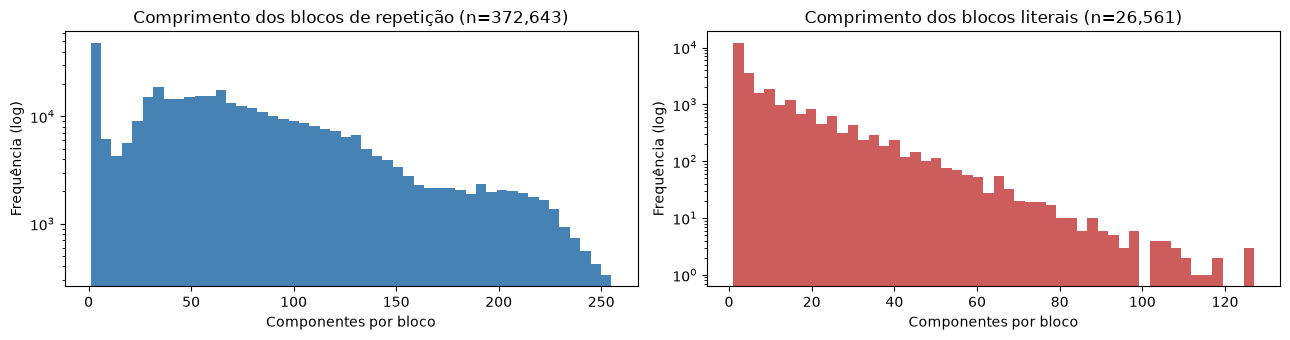

In [9]:
# --- Por que a razão é modesta: estatística das corridas ---

corridas = []
literais = []

for y in range(altura):
    for c in range(3):
        for v in comprimir_sequencia(imagem[y, :, c].tolist()):
            if v > 0:
                corridas.append(v)
            elif v < 0:
                literais.append(-v)

corridas = np.array(corridas)
literais = np.array(literais)

px_em_corrida = int(corridas.sum())
px_em_literal = int(literais.sum())
total_px = px_em_corrida + px_em_literal

print("ANATOMIA DO FLUXO CODIFICADO")
print("-" * 58)
print(f"Blocos de repetição : {corridas.size:>9,}  "
      f"cobrindo {px_em_corrida:>9,} componentes "
      f"({px_em_corrida / total_px * 100:5.1f}%)")
print(f"Blocos literais     : {literais.size:>9,}  "
      f"cobrindo {px_em_literal:>9,} componentes "
      f"({px_em_literal / total_px * 100:5.1f}%)")
print()
print(f"Comprimento médio das repetições : {corridas.mean():.2f} componentes")
print(f"Comprimento médio dos literais   : {literais.mean():.2f} componentes")
print(f"Maior repetição encontrada       : {corridas.max()}")
print()
print("Cada bloco de repetição economiza (comprimento - 2) bytes.")
print("Cada bloco literal custa 1 byte extra.")
economia = int((corridas - 2).sum())
custo = literais.size
print(f"  economia total : {economia:>10,} bytes")
print(f"  custo total    : {custo:>10,} bytes")
print(f"  saldo          : {economia - custo:>+10,} bytes")

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.5))
eixos[0].hist(corridas, bins=50, color="steelblue")
eixos[0].set_title(f"Comprimento dos blocos de repetição (n={corridas.size:,})")
eixos[0].set_xlabel("Componentes por bloco")
eixos[0].set_yscale("log")
eixos[1].hist(literais, bins=50, color="indianred")
eixos[1].set_title(f"Comprimento dos blocos literais (n={literais.size:,})")
eixos[1].set_xlabel("Componentes por bloco")
eixos[1].set_yscale("log")
for ax in eixos:
    ax.set_ylabel("Frequência (log)")
plt.tight_layout()
plt.show()

## 5. Os dois extremos do RLE

O desempenho do RLE depende inteiramente da **natureza do conteúdo**, não do
formato. A apostila de formatos explica por quê: uma imagem fotográfica se
caracteriza pela variação suave e contínua da cor de píxel para píxel, que é
"exatamente a situação mais desfavorável ao emprego de algoritmos de compressão
das famílias RLE ou LZ".

As duas células seguintes demonstram os extremos usando material das atividades
anteriores:

**Pior caso** — a imagem de ruído aleatório da Atividade 1. Sem nenhuma
repetição, o RLE só gera blocos literais, e cada bloco custa 1 byte de contador.
O arquivo comprimido fica **maior** que o original.

**Melhor caso** — uma imagem binarizada como a das Atividades 05-2 e 06. Com
apenas dois valores possíveis e grandes regiões uniformes, as corridas são
longuíssimas.

Mesmo algoritmo, mesma implementação, resultados em ordens de grandeza
diferentes.

In [10]:
# --- Pior caso: ruído aleatório ---

rng = np.random.default_rng(42)
ruido = rng.integers(0, 256, size=(100, 100, 3), dtype=np.uint8)

bytes_ruido = 0
for y in range(ruido.shape[0]):
    for c in range(3):
        bytes_ruido += len(comprimir_sequencia(ruido[y, :, c].tolist()))

original_ruido = ruido.size

print("PIOR CASO — ruído aleatório uniforme (como na Atividade 1)")
print("-" * 58)
print(f"Original (P6)  : {original_ruido:>10,} bytes")
print(f"Comprimido RLE : {bytes_ruido:>10,} bytes")
print(f"Variação       : {bytes_ruido - original_ruido:>+10,} bytes "
      f"({(bytes_ruido / original_ruido - 1) * 100:+.2f}%)")
print()
print("O RLE EXPANDE os dados. Sem repetições, tudo vira bloco literal, e")
print(f"cada bloco de até {MAX_BLOCO} valores carrega 1 byte de contador —")
print(f"um acréscimo teórico de 1/{MAX_BLOCO} = {1 / MAX_BLOCO * 100:.2f}%.")
print()
print("É por isso que formatos reais só aplicam RLE quando ele de fato")
print("reduz o tamanho, mantendo o bloco sem compressão caso contrário.")

PIOR CASO — ruído aleatório uniforme (como na Atividade 1)
----------------------------------------------------------
Original (P6)  :     30,000 bytes
Comprimido RLE :     30,404 bytes
Variação       :       +404 bytes (+1.35%)

O RLE EXPANDE os dados. Sem repetições, tudo vira bloco literal, e
cada bloco de até 127 valores carrega 1 byte de contador —
um acréscimo teórico de 1/127 = 0.79%.

É por isso que formatos reais só aplicam RLE quando ele de fato
reduz o tamanho, mantendo o bloco sem compressão caso contrário.


MELHOR CASO — imagem binarizada (como na Atividade 06)
----------------------------------------------------------
Original (P6)  :    463,203 bytes
Comprimido RLE :     35,733 bytes
Razão          :      12.96x
Economia       :       92.3%


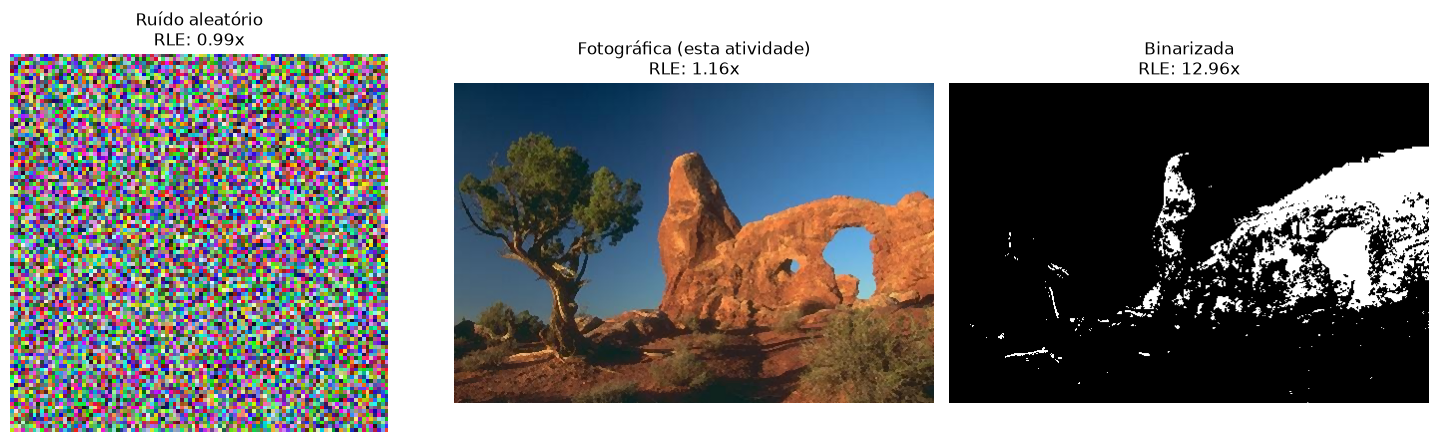


Três conteúdos, um mesmo algoritmo, três ordens de grandeza de
resultado. O que determina a compressão é a redundância dos dados,
não a escolha do compressor.


In [11]:
# --- Melhor caso: imagem binarizada ---

# Binariza o canal de luminância da própria imagem (como na Atividade 06)
cinza = np.rint(imagem.mean(axis=2)).astype(np.uint8)
binaria = np.where(cinza > 128, 255, 0).astype(np.uint8)
binaria_rgb = np.stack([binaria] * 3, axis=2)

bytes_bin = 0
for y in range(binaria_rgb.shape[0]):
    for c in range(3):
        bytes_bin += len(comprimir_sequencia(binaria_rgb[y, :, c].tolist()))

original_bin = binaria_rgb.size

print("MELHOR CASO — imagem binarizada (como na Atividade 06)")
print("-" * 58)
print(f"Original (P6)  : {original_bin:>10,} bytes")
print(f"Comprimido RLE : {bytes_bin:>10,} bytes")
print(f"Razão          : {original_bin / bytes_bin:>10.2f}x")
print(f"Economia       : {(1 - bytes_bin / original_bin) * 100:>10.1f}%")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, img, titulo, razao in zip(
        eixos,
        (ruido, imagem, binaria_rgb),
        ("Ruído aleatório", "Fotográfica (esta atividade)", "Binarizada"),
        (original_ruido / bytes_ruido, tam_p6 / tam_rle, original_bin / bytes_bin)):
    ax.imshow(img)
    ax.set_title(f"{titulo}\nRLE: {razao:.2f}x")
    ax.axis("off")
plt.tight_layout()
plt.show()

print()
print("Três conteúdos, um mesmo algoritmo, três ordens de grandeza de")
print("resultado. O que determina a compressão é a redundância dos dados,")
print("não a escolha do compressor.")

## 6. A melhoria sugerida pelo material

O material encerra com uma observação e uma proposta:

> Este método funciona bem quando as áreas de cores iguais são horizontais. Mas,
> caso contrário, o arquivo final poderá ser maior. Como melhoria, poderíamos
> selecionar modo de varredura da imagem inicial: por linhas, por colunas ou
> pelas diagonais.

A razão é que o RLE enxerga apenas uma dimensão. Uma imagem com faixas
**verticais** uniformes tem corridas longuíssimas na leitura por colunas e
corridas de comprimento 1 na leitura por linhas — e vice-versa.

A célula seguinte testa as duas varreduras sobre a imagem real e sobre dois
casos sintéticos construídos para favorecer cada uma. A varredura por colunas
quebra a decodificação linha a linha que o material descreve, de modo que seria
preciso registrar o modo no cabeçalho; aqui o interesse é medir o efeito, não
mudar o formato.

Conteúdo                    Original    Por linhas   Por colunas    Melhor
--------------------------------------------------------------------------
Faixas horizontais            43,200          720         8,640    linhas
                                           60.00x         5.00x
Faixas verticais              43,200        8,640           720   colunas
                                            5.00x        60.00x
Imagem real                  463,203      399,213       441,936    linhas
                                            1.16x         1.05x


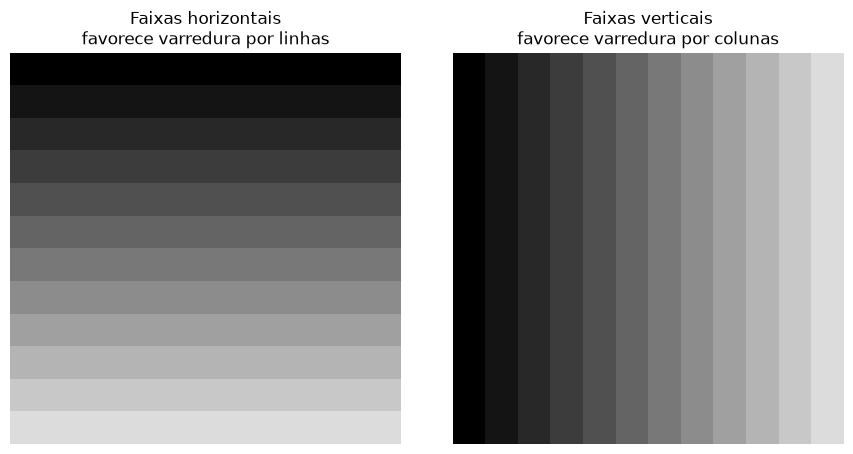


Os dois casos sintéticos têm a mesma quantidade de informação e a
mesma estrutura — apenas girada 90 graus. A diferença de compressão
entre eles mostra que o RLE não é sensível ao conteúdo, e sim ao
alinhamento entre a redundância e a direção da varredura.


In [12]:
# --- Comparação de modos de varredura ---

def tamanho_rle(imagem, por_colunas=False):
    """Mede o tamanho do fluxo RLE varrendo por linhas ou por colunas."""
    alvo = np.transpose(imagem, (1, 0, 2)) if por_colunas else imagem
    total = 0
    for i in range(alvo.shape[0]):
        for c in range(3):
            total += len(comprimir_sequencia(alvo[i, :, c].tolist()))
    return total


# Casos sintéticos: faixas horizontais e faixas verticais
faixas_h = np.zeros((120, 120, 3), dtype=np.uint8)
faixas_v = np.zeros((120, 120, 3), dtype=np.uint8)
for k in range(0, 120, 10):
    faixas_h[k:k + 10, :, :] = (k * 2) % 256
    faixas_v[:, k:k + 10, :] = (k * 2) % 256

casos = [
    ("Faixas horizontais", faixas_h),
    ("Faixas verticais", faixas_v),
    ("Imagem real", imagem),
]

print(f"{'Conteúdo':<24}{'Original':>12}{'Por linhas':>14}{'Por colunas':>14}"
      f"{'Melhor':>10}")
print("-" * 74)
for nome, img in casos:
    orig = img.size
    por_l = tamanho_rle(img, por_colunas=False)
    por_c = tamanho_rle(img, por_colunas=True)
    melhor = "linhas" if por_l < por_c else "colunas"
    print(f"{nome:<24}{orig:>12,}{por_l:>13,}{por_c:>14,}{melhor:>10}")
    print(f"{'':<24}{'':>12}{orig / por_l:>12.2f}x{orig / por_c:>13.2f}x")

fig, eixos = plt.subplots(1, 2, figsize=(9, 4.5))
eixos[0].imshow(faixas_h)
eixos[0].set_title("Faixas horizontais\nfavorece varredura por linhas")
eixos[1].imshow(faixas_v)
eixos[1].set_title("Faixas verticais\nfavorece varredura por colunas")
for ax in eixos:
    ax.axis("off")
plt.tight_layout()
plt.show()

print()
print("Os dois casos sintéticos têm a mesma quantidade de informação e a")
print("mesma estrutura — apenas girada 90 graus. A diferença de compressão")
print("entre eles mostra que o RLE não é sensível ao conteúdo, e sim ao")
print("alinhamento entre a redundância e a direção da varredura.")

In [13]:
# --- Verificação final dos arquivos gerados ---

print(f"{'Arquivo':<40}{'Tamanho':>14}{'Observação':>22}")
print("-" * 78)
print(f"{ARQUIVO_ENTRADA.name:<40}{tam_p3:>13,}B{'entrada, P3 ASCII':>22}")
print(f"{ARQUIVO_RLE.name:<40}{tam_rle:>13,}B{'comprimido':>22}")
print(f"{PPM_RECUPERADO.name:<40}"
      f"{PPM_RECUPERADO.stat().st_size:>13,}B{'reconstruído':>22}")
print()

entrada_final, mv1 = ler_ppm_p3(ARQUIVO_ENTRADA)
saida_final, mv2 = ler_ppm_p3(PPM_RECUPERADO)

print("VALIDAÇÃO FINAL")
print("-" * 54)
print(f"Dimensões idênticas     : {entrada_final.shape == saida_final.shape}")
print(f"maxval idêntico         : {mv1 == mv2}")
print(f"Conteúdo bit a bit igual: {np.array_equal(entrada_final, saida_final)}")
print()
print(f"Razão de compressão     : {tam_p6 / tam_rle:.3f}x  (contra P6 binário)")

Arquivo                                        Tamanho            Observação
------------------------------------------------------------------------------
Fig4.ppm                                    1,557,748B     entrada, P3 ASCII
Fig4.rle                                      399,229B            comprimido
Fig4_recuperada.ppm                         1,538,495B          reconstruído

VALIDAÇÃO FINAL
------------------------------------------------------
Dimensões idênticas     : True
maxval idêntico         : True
Conteúdo bit a bit igual: True

Razão de compressão     : 1.160x  (contra P6 binário)


---

## Conclusões

### Arquivos gerados

| Arquivo | Conteúdo |
|---------|----------|
| `Fig4.rle` | imagem comprimida, cabeçalho ASCII + fluxo de bytes |
| `Fig4_recuperada.ppm` | reconstrução a partir do RLE, idêntica à original |

### Validação da implementação

O codificador foi testado contra os dois exemplos numéricos do material antes
de ser aplicado à imagem: a sequência de 23 valores e o caso das 600 repetições
divididas em grupos de 127. Ambos conferem posição a posição.

O `?` que o material deixa em aberto resolve como `−1`: um bloco literal de um
único valor, já que a sequência termina ali. A incógnita existe porque o
contador de um bloco literal só pode ser escrito depois de se saber quantos
valores distintos virão — informação que só aparece ao encontrar a próxima
repetição ou o fim da linha.

### Compressão sem perda

O round-trip foi verificado em dois níveis: a matriz descomprimida é bit a bit
idêntica à original, e o PPM reconstruído, relido do disco, também. Nenhum byte
sobrou no fluxo ao final da decodificação, o que confirma que o formato é
consumido exatamente.

Isso distingue o RLE das operações das atividades anteriores. Quantização,
binarização e conversão para cinza **destroem** informação irreversivelmente. O
RLE apenas a **reescreve** de forma mais compacta — toda ela continua lá.

### O resultado, sem maquiagem

Sobre esta imagem, o RLE entrega razão modesta contra o P6 binário. Não é falha
da implementação: é a natureza do algoritmo diante de conteúdo fotográfico. A
análise do fluxo mostra onde o ganho se perde — boa parte dos componentes cai em
blocos literais, e cada um deles custa 1 byte extra em vez de economizar.

A comparação entre os três conteúdos deixa o ponto claro: o mesmo código produz
expansão sobre ruído aleatório, ganho modesto sobre a imagem fotográfica e
compressão de uma ordem de grandeza sobre uma imagem binarizada. **O que
determina a compressão é a redundância dos dados, não o compressor.**

Vale registrar a armadilha de medição: comparar o RLE contra o arquivo P3 de
entrada daria um número muito mais impressionante, mas enganoso — ele mediria
sobretudo o abandono da representação textual. A referência correta é o P6
binário, que é a quantidade de dados que o algoritmo efetivamente recebe.

### Sobre a direção da varredura

O teste com faixas horizontais e verticais confirma a observação final do
material. As duas imagens sintéticas carregam a mesma informação, diferindo
apenas por uma rotação de 90 graus, e produzem resultados de compressão
opostos conforme a varredura escolhida.

Isso expõe a limitação de fundo do RLE: ele é um algoritmo **unidimensional**
aplicado a dados bidimensionais. A redundância espacial que existe na vertical é
invisível para ele quando a varredura é horizontal. Famílias como LZ capturam
padrões repetidos a qualquer distância, e a Transformada Discreta do Co-seno,
empregada pelo JPEG, trabalha sobre blocos 2D — por isso lidam muito melhor com
imagens de tom contínuo, como a apostila de formatos detalha.